In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

np.set_printoptions(precision=3, suppress=True)

In [4]:
iris = load_iris()
X_all, y_all = iris.data, iris.target
print(X_all.shape, y_all.shape, iris.target_names)

(150, 4) (150,) ['setosa' 'versicolor' 'virginica']


a, b, c = 5, 8, 7

In [5]:
from matplotlib.patches import Patch, Circle
from matplotlib.colors import LinearSegmentedColormap, to_rgb

SPECIES = ["setosa", "versicolor", "virginica"]
COLORS  = ["#2a78d6", "#eb6834", "#1baf7a"]   # one colour per species, used in every plot
MARKERS = ["o", "s", "^"]                     # ...and one shape (easier to read on a projector)
INK, INK2, MUTED, LINE, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#c3c2b7", "#e1e0d9", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 100, "font.size": 10, "lines.linewidth": 2,
    "axes.edgecolor": LINE, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.titlepad": 10, "axes.labelcolor": INK2, "axes.labelsize": 10,
    "xtick.color": LINE, "ytick.color": LINE, "xtick.labelcolor": MUTED, "ytick.labelcolor": MUTED,
    "legend.frameon": True, "legend.facecolor": SURFACE, "legend.edgecolor": "none",
    "legend.framealpha": 0.88, "legend.fontsize": 9,
})

In [6]:
def _scatter_species(ax, X, y):
    for k in range (3):
        m = y == k
        ax.scatter(X[m,0], X[m,1], s=42, c=COLORS[k], marker=MARKERS[k],
                    edgecolors=SURFACE, linewidths=0.9, label=SPECIES[k], zorder=3)
def _tint(color, amount):
    c, s = to_rgb(color), to_rgb(SURFACE)
    return tuple(si + amount * (ci -si) for ci, si in zip(c, s))

def _petal_axes(ax):
    ax.set_xlabel("petal length (cm)")
    ax.set_xlabel("petal width (cm)")
    ax.set_xlim(0.5, 7.5)
    ax.set_ylim(-0.2, 2.9)

def plot_flowers(X, y):
    fig, ax = plt.subplots(figsize=(5.8, 4.2))
    _scatter_species(ax, X, y)
    _petal_axes(ax)
    ax.set_title("150 iris flowers, two petal measurements")
    ax.legend(loc='upper left')
    plt.show()

def plot_regions(predict, X, y, target, title='', ax=None, legend=True):
    """Shade where predict(X_cm) > 0.5, i.e. where the model answers 'yes, this is a <target>'."""
    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(5.8, 4.2))
    g0, g1 = np.meshgrid(np.linspace(0.5, 7.5, 350), np.linspace(-0.2, 2.9, 350))
    P = np.asarray(predict(np.c_[g0.ravel(), g1.ravel()]), dtype=float).reshape(g0.shape)
    tint = _tint(COLORS[target], 0.24)
    ax.contourf(g0, g1, (P > 0.5).astype(float), levels=[-0.5, 0.5, 1.5], colors=[SURFACE, tint], zorder=2)
    if P.min() < 0.5 <P.max():
        ax.contour(g0, g1, P, levels=[0.5], colors=INK, linewidths=1.4, zorder=2)
    ax.grid(False)
    _scatter_species(ax, X, y)
    _petal_axes(ax)
    acc = np.mean((np.asarray(predict(X), dtype=float).ravel() > 0.5) == (y == target))
    ax.set_title(f'{title}\naccuracy {acc:.1%}' if title else f'accuracy {acc:.1%}')
    if legend:
        handles = ax.get_legend_handles_labels()[0]
        handles.append(Patch(facecolor=tint, edgecolor='none', label=f'model says:{SPECIES[target]}'))
        ax.legend(handles=handles, loc='upper left')
    if standalone:
        plt.show()

def show_perceptron(w, b, mistakes, X, y, target):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={'width_ratios': [1, 1.15]})
    epochs = np.arange(1, len(mistakes) + 1)
    ax1.plot(epochs, mistakes, color=INK2, marker='o', markersize=5.5, markeredgecolor=SURFACE, clip_on=False)
    ax1.set_xlabel('epoch')
    ax1.set_ylabel('mistakes during the epoch')
    ax1.set_ylim(0, max(10, max(mistakes) * 1.15))
    ax1.set_title(f'Perceptron learning: {SPECIES[target]} vs. the rest\nmistakes per epoch')
    plot_regions(lambda Xq: (Xq @ w +b > 0).astype(float), X, y, target, title='Final decision boundary', ax=ax2)
    plt.tight_layout()
    plt.show

def draw_network(sizes, in_labels, out_labels, out_colors, hidden_labels=None, title=''):
    xs = np.arange(len(sizes)) * 2.4
    ys = [np.linspace((s - 1) / 2, -(s - 1) / 2, s) * 0.9 for s in sizes]
    top = max(len(l) for l in ys) * 0.45 + 0.4
    fig, ax = plt.subplots(figsize=(7.2, 0.55 * max(sizes) + 1.5))
    for i in range(len(sizes) -1):
        for ya in ys[i]:
            for yb in ys[i+1]:
                ax.plot([xs[i], xs[i + 1]], [ya, yb], color=LINE, lw=0.9, zorder=1)
    r = 0.24
    for i, (x, layer) in enumerate(zip(xs, ys)):
        for j, yj in enumerate(layer):
            if i == len(sizes) - 1:
                face, edge = _tint(out_colors[j], 0.3), out_colors[j]
            else:
                face, edge = ('#f0efec' if i else SURFACE), INK2
            ax.add_patch(Circle((x, yj), r, facecolor=face, edgecolor=edge, lw=1.6, zorder=3))
            if i == 0:
                ax.text(x - r - 0.15, yj, in_labels[j], ha='right', va='center', color=INK)
            elif i == len(sizes) - 1:
                ax.text(x + r + 0.15, yj, out_labels[j], ha='left', va='center', color=INK)
            elif hidden_labels:
                ax.text(x, yj, hidden_labels[j], ha='center', va='center', color=INK, fontsize=9, zorder=4)
    names = ['inputs'] + ['hidden layer'] * (len(sizes) - 2) + ['output layer']
    bottom = min(l.min() for l in ys) - r - 0.25
    for x, name, s in zip(xs, names, sizes):
        unit = 'value' if name == 'inputs' else 'neuron'
        ax.text(x, bottom, f"{name}\n{s} {unit}{'s' if s > 1 else ''}", ha='center', va='top', color=MUTED, fontsize=9)
    ax.set_aspect('equal')
    ax.set_xlim(xs[0] - 2.6, xs[-1] + 2.4)
    ax.set_ylim(bottom - 0.75, -bottom + 0.2)
    if title:
        ax.set_title(title)
    plt.show()

def show_training(losses, predict, X, y, target):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={'width_ratios':[1, 1.5]})
    ax1.plot(np.arange(1, len(losses) + 1), losses, color=INK2)
    ax1.set_xlabel('epoch')
    ax1.set_ylabel('cross entropy loss')
    ax1.set_ylim(0, max(losses) * 1.08)
    ax1.set_title('1 The loss while it learns')
    plot_regions(predict, X, y, target, title='2 What it learned', ax=ax2)
    plt.tight_layout()
    plt.show()

def plot_hidden_space(H, y, params, target):
    if H.shape[1] != 2:
        print(f'The hidden layer has {H.shape[1]} neurons: too many dimensions to draw. Use n_hidden=2')
        return
    W2, b2 = params[2], params[3]
    fig, ax = plt.subplots(figsize=(5.8, 4.8))
    g0, g1 = np.meshgrid(np.linspace(-0.6, 1.06, 300), np.linspace(-0.6, 1.06, 300))
    Z = (np.c_[g0.ravel(), g1.ravel()] @ W2 + b2).reshape(g0.shape)
    tint = _tint(COLORS[Target], 0.24)
    ax.countourf(g0, g1, (Z > 0).astype(float), levels=[-0.5, 0.5, 1.5], colors=[SURFACE, tint], zorder=0)
    ax.grid(False)
    _scatter_species(ax, H, y)
    ax.set_xlim(-0.6, 1.06)
    ax.set_ylim(-0.6, 1.06)
    ax.set_xlabel('h1 = the output of hidden neuron 1')
    ax.set_xlabel('h2 = the output of hidden neuron 2')
    ax.set_title('3 The flowers as the hidden layer sees them\n(the black line is the output neuron)')
    handles = ax.get_legend_handles_labels()[0]
    handles.append(Patch(facecolor=tint, edgecolor='none', label=f'mpdel says: {SPECIES[target]}'))
    ax.legend(handles=handles, loc='best')
    plt.show()

def show_results(losses, y_true, y_pred):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.3), gridspec_kw={'width_ratios': [1.25, 1]})
    ax1.plot(np.arange(1, len(losses) + 1), losses, color=INK2)
    ax1.set_xlabel('epoch')
    ax1.set_ylabel('cross_entropy loss')
    ax1.set_ylim(0, max(losses) * 1.08)
    ax1.set_title('Training loss')
    cm = np.zeros((3, 3), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    cmap = LinearSegmentedColormap.from_list('ramp', [SURFACE, '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#104281'])
    ax2.imshow(cm, cmap=cmap, vmin=0, vmax=max(cm.max(), 1))
    for i in range(3):
        for j in range(3):
            dark = cm[i, j] > 0.55 * cm.max()
            ax2.text(j, i, cm[i, j], ha='center', va='center', fontsize=13, fontweigth='bold',
                        color='white' if dark else (INK if cm[i,j] else MUTED))
    ax2.set_xticks(range(3), SPECIES)
    ax2.set_yticks(range(3), SPECIES)
    ax2.set_xticks(np.arange(-0.5, 3), minor=True)
    ax2.set_yticks(np.arange(-0.5, 3), minor=True)
    ax2.grid(which='minor', color=SURFACE, linewidth=3)
    ax2.grid(which='major', visible=False)
    ax2.tick_paarams(which='both', length=0)
    for s in ax2.spines.values():
        s.set_visible(False)
    ax2.set_xlabel('Predicted species')
    ax2.set_ylabel('true species')
    ax2.set_title('Test flowers: true vs. predicted')
    plt.tigth_layout()
    plt.show()

def check_output_neuron(W2, b2):
    W2, b2 = np.asarray(W2, dtype=float).reshape(2, 1), np.asarray(b2, dtype=float).reshape(1)
    ok = True
    print(' h1 h1 | output wanted')
    for h1, h2, want in [(0, 0, 0), (1, 0, 1), (0, 1, 0), (1, 1, 0)]:
        out = int((np.array([h1, h2]) @ W2 + b2).item() > 0)
        ok = ok and out == want
    if ok:
        print("\n✅ Your output neuron computes  h1 AND NOT h2")
    else:
        print("\n❌ Not yet. Hint: a positive weight for h1, a negative weight for h2,"
            " and a bias that keeps the neuron off when h1 = 0.")


_FWD_X = np.array([[0.5, -1.0], [2.0, 0.3], [-1.2, 0.8]])
_FWD_P = [np.array([[0.4, -0.7], [1.2, 0.5]]), np.array([0.1, -0.2]), np.array([[1.5], [-2.0]]), np.array([0.3])]
_FWD_H = np.array([[0.289050497374996, 0.259225100817846], [0.7790261077798122, 0.19000156601531298], [0.6410674063348171, 0.7388500060842489]])
_FWD_Y = np.array([[0.5535749291196774], [0.7481059462133204], [0.4461845376865776]])
_FWD_Z2 = np.array([[0.21512554442680198], [1.0885360296390922], [-0.21609890266627213]])
_BWD_Y = np.array([[1.0], [0.0], [1.0]])
_BWD_G = [np.array([[0.18230690861743198, -0.21042427326421692], [0.014214413278599018, -0.023185921900629725]]), np.array([-0.04519557365334608, 0.05163380175036876]), np.array([[0.03290721089782937], [-0.12758994679349683]]), np.array([-0.08404486232680819])]


def _explain(e):
    msg = str(e).lower()
    if "ellipsis" in msg:
        return "❌ Replace the  ...  placeholders with your code first."
    hint = ""
    if "broadcast" in msg:
        hint = "\n   Hint: use @ for a matrix product (* multiplies element by element)."
    elif "matmul" in msg or "mismatch" in msg or "not aligned" in msg:
        hint = "\n   Hint: the shapes don't line up. Do you need a transpose (.T)?"
    return f"❌ It doesn't run yet -> {type(e).__name__}: {e}{hint}"


def check_forward(forward):
    try:
        H, Y_hat = forward(_FWD_X.copy(), [p.copy() for p in _FWD_P])
    except Exception as e:
        print(_explain(e))
        return
    if H is Ellipsis or Y_hat is Ellipsis:
        print("❌ Replace the  ...  placeholders with your code first.")
        return
    H, Y_hat = np.asarray(H, dtype=float), np.asarray(Y_hat, dtype=float)
    if H.shape != _FWD_H.shape:
        print(f"❌ H has shape {H.shape}, expected {_FWD_H.shape} (one row per flower, one column per hidden neuron).")
    elif not np.allclose(H, _FWD_H):
        print("❌ H has the right shape but the wrong values. "
            "Hidden layer = weighted sum (X @ W1) + bias, passed through the sigmoid.")
    elif Y_hat.shape != _FWD_Y.shape or not np.allclose(Y_hat, _FWD_Y):
        print("❌ H is right, but Y_hat is not. Output layer = weighted sum of H (H @ W2) + bias, "
            "passed through out_act.")
    else:
        try:
            _, Z_out = forward(_FWD_X.copy(), [p.copy() for p in _FWD_P], out_act=lambda z: z)
            uses_out_act = np.allclose(np.asarray(Z_out, dtype=float), _FWD_Z2)
        except Exception:
            uses_out_act = False
        if uses_out_act:
            print("✅ forward() is correct!")
        else:
            print("❌ Almost! At the output, use out_act(...) instead of sigmoid(...), "
                "so that Part 4 can swap in a different output activation.")


def check_backward(backward):
    try:
        grads = backward(_FWD_X.copy(), _BWD_Y.copy(), _FWD_H.copy(), _FWD_Y.copy(), [p.copy() for p in _FWD_P])
        dW1, db1, dW2, db2 = [np.asarray(g, dtype=float) for g in grads]
    except Exception as e:
        print(_explain(e))
        return
    if not (np.allclose(dW2, _BWD_G[2]) and np.allclose(db2, _BWD_G[3])):
        print("❌ The output-layer lines were given to you: make sure they weren't changed.")
    elif db1.shape != _BWD_G[1].shape or not np.allclose(db1, _BWD_G[1]):
        print("❌ delta1 is not right. It is (delta2 sent back through W2) times the slope of the sigmoid, H * (1 - H). "
            "Use @ with W2.T to send it back, and * for the element-wise product.")
    elif dW1.shape != _BWD_G[0].shape or not np.allclose(dW1, _BWD_G[0]):
        print("❌ delta1 is right, but dW1 is not. Mirror  dW2 = H.T @ delta2  one layer down: "
            "the input of the hidden layer is X.")
    else:
        print("✅ backward() is correct. You just implemented backpropagation!")

def plot_step_vs_sigmoid():
    z = np.linspace(-6, 6, 601)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11,3.7), sharey=True)
    ax1.plot(z, (z > 0).astype(float), color=INK2)
    ax1.set_title('Step (perceptron)')
    ax1.text(-5.7, 0.62, 'flat everywhere except the jump:\na small nudge to w changes nothing,\n'
             'so there is no hint which way to move', color=INK2, fontsize=9.5, va='center')    
    s = 1 / (1 + np.exp(-z))
    ax2.plot(z, s, color=INK)
    z0 = 1
    s0 = 1 / (1 + np.exp(-z0))
    zz = np.array([z0 -1.8, z0+ 1.8])
    ax2.plot(zz, s0 + s0 * (1 -s0) * (zz - z0), color=MUTED, lw=1.3)
    ax2.scatter([z0], [s0], s=40, color=INK, zorder=3)
    ax2.set_title('Sigmoid (neutral network)')
    ax2.text(-5.7, 0.62, 'a slope everywhere (gray line):\nit tellsus which way to nudge\neach weight',
             color=INK2, fontsize=9.5, va='center')
    for ax in (ax1, ax2):
        ax.set_xlabel('z = wx + b')
        ax.set_ylim(-0.08, 1.1)
    ax1.set_label('neuron output')
    plt.tight_layout()
    plt.show()


print("Helpers loaded ✅")

Helpers loaded ✅


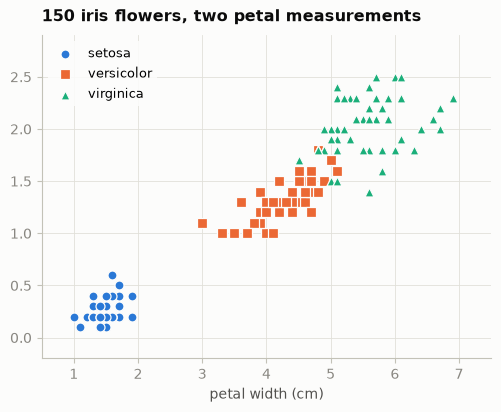

In [7]:
X = X_all[:, 2:] # petal length, petal widtn (cm)
plot_flowers(X, y_all)

In [8]:
X

array([[1.4, 0.2],
       [1.4, 0.2],
       [1.3, 0.2],
       [1.5, 0.2],
       [1.4, 0.2],
       [1.7, 0.4],
       [1.4, 0.3],
       [1.5, 0.2],
       [1.4, 0.2],
       [1.5, 0.1],
       [1.5, 0.2],
       [1.6, 0.2],
       [1.4, 0.1],
       [1.1, 0.1],
       [1.2, 0.2],
       [1.5, 0.4],
       [1.3, 0.4],
       [1.4, 0.3],
       [1.7, 0.3],
       [1.5, 0.3],
       [1.7, 0.2],
       [1.5, 0.4],
       [1. , 0.2],
       [1.7, 0.5],
       [1.9, 0.2],
       [1.6, 0.2],
       [1.6, 0.4],
       [1.5, 0.2],
       [1.4, 0.2],
       [1.6, 0.2],
       [1.6, 0.2],
       [1.5, 0.4],
       [1.5, 0.1],
       [1.4, 0.2],
       [1.5, 0.2],
       [1.2, 0.2],
       [1.3, 0.2],
       [1.4, 0.1],
       [1.3, 0.2],
       [1.5, 0.2],
       [1.3, 0.3],
       [1.3, 0.3],
       [1.3, 0.2],
       [1.6, 0.6],
       [1.9, 0.4],
       [1.4, 0.3],
       [1.6, 0.2],
       [1.4, 0.2],
       [1.5, 0.2],
       [1.4, 0.2],
       [4.7, 1.4],
       [4.5, 1.5],
       [4.9,

In [9]:
def step(z):
    return (z > 0).astype(float)

def train_perceptron(X, y, epochs=30, lr=0.1, seed=0):
    rng = np.random.default_rng(seed)
    w, b = np.zeros(X.shape[1]), 0.0
    mistakes_per_epoch = []
    for epoch in range (epochs):
        mistakes = 0
        for i in rng.permutation(len(X)):
            y_hat = step(X[i] @ w +b)
            update = lr * (y[i] - y_hat)
            w += update * X[i]
            b += update
            mistakes += int(y_hat != y[i])
        mistakes_per_epoch.append(mistakes)
    return w, b, mistakes_per_epoch

mistakes per epoch: [8, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


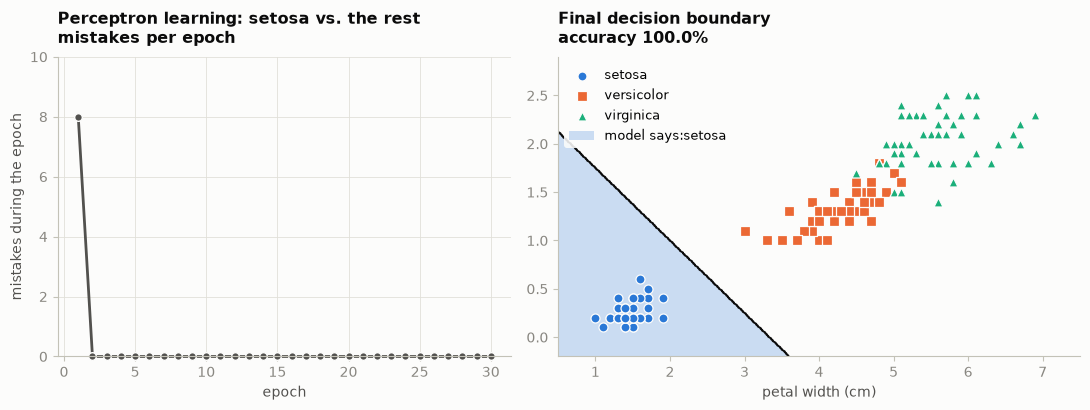

In [10]:
y_setosa = (y_all == 0).astype(float)
w, b, mistakes = train_perceptron(X, y_setosa)
print('mistakes per epoch:', mistakes)
show_perceptron(w,b, mistakes, X, y_all, target=0)

mistakes per epoch: [65, 74, 70, 64, 59, 58, 53, 54, 52, 58, 56, 60, 56, 56, 52, 63, 56, 66, 48, 58, 60, 63, 56, 59, 49, 57, 54, 61, 63, 59]


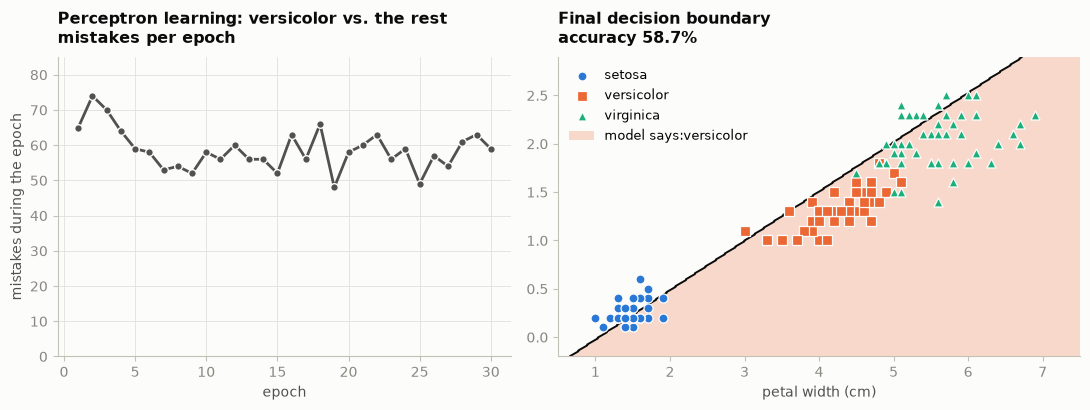

In [11]:
y_versi = (y_all == 1).astype(float)
w, b, mistakes = train_perceptron(X, y_versi)
print('mistakes per epoch:', mistakes)
show_perceptron(w, b, mistakes, X, y_all, target=1)

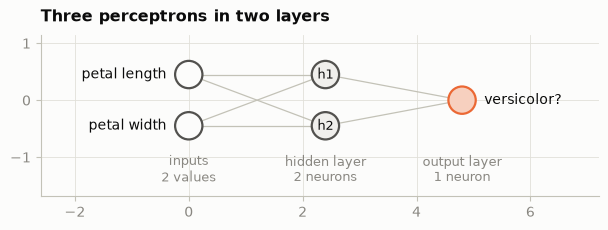

In [12]:
draw_network([2, 2, 1], in_labels=['petal length', 'petal width'], hidden_labels=['h1', 'h2'],
            out_labels=['versicolor?'], out_colors=[COLORS[1]], title='Three perceptrons in two layers'
            )

In [13]:
W1 = np.array([[1.0, 0.0],
               [0.0, 1.0]])

b1 = np.array([-2.5, -1.75])

W2 = np.array([[1.0], [-2.0]])
b2 = np.array([-0.5])

check_output_neuron(W2, b2)


 h1 h1 | output wanted

✅ Your output neuron computes  h1 AND NOT h2


In [14]:
def hand_network(X):
    H = step( X @ W1 + b1)
    return step(H @ W2 + b2)

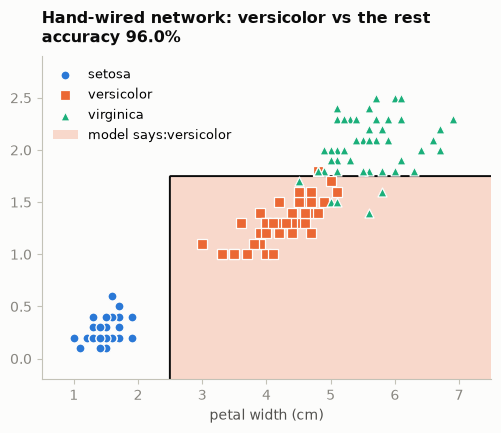

In [15]:
plot_regions(hand_network, X, y_all, target=1, title='Hand-wired network: versicolor vs the rest')

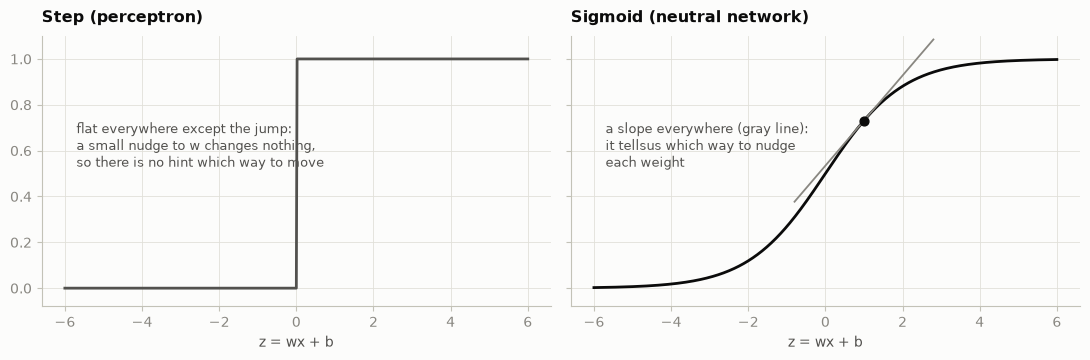

In [16]:
plot_step_vs_sigmoid()

In [17]:
mu, sd = X.mean(axis=0), X.std(axis=0)
Xs = (X - mu) / sd
Y_versi = y_versi.reshape(-1, 1)

In [18]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def init_params(n_in, n_hidden, n_out, seed=0):
    rng = np.random.default_rng(seed)
    W1 = rng.normal(0, 1, (n_in, n_hidden)); b1 = np.zeros(n_hidden)
    W2 = rng.normal(0, 1, (n_hidden, n_out)); b2 = np.zeros(n_out)
    return [W1, b1, W2, b2]

def cross_entropy(Y, Y_hat):
    """Average loss: small when we give a high probability to the right answer."""
    eps = 1e-12
    if Y.shape[1] == 1:
        return -np.mean(Y * np.log(Y_hat + eps) + (1 - Y) * np.log(1 - Y_hat + eps))
    return -np.mean(np.sum(Y * np.log(Y_hat + eps), axis=1))

Ejercicio. Implementar una función análoga a hand_network, pero usando la sigmoid en la capa oculta (hidden layer) y out_act (sigmoid por el momento) en la capa de salida.

In [19]:
def forward(X, params, out_act=sigmoid):
    W1, b1, W2, b2 = params
    H = sigmoid(X @ W1 + b1) #sigmoid sirve para activar
    Y_hat = out_act(H @ W2 + b2) #al igual que sigmout, out_act activa 
    return H, Y_hat

check_forward(forward)

✅ forward() is correct!


In [ ]:
draw_network(
    [4, 8, 3],
    in_labels=['sepal lenght', 'sepal width', 'petal lenght', 'petal width'],
    out_labels=SPECIES,
    out_colors=COLORS,
    title='The full network: 4 8 3'
)